In [1]:
import tensorflow as ts
from tensorflow.keras import datasets,layers,models
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(X_train,y_train),(X_test,y_test)=datasets.cifar10.load_data()

In [3]:
X_test.shape

(10000, 32, 32, 3)

In [4]:
X_train.shape

(50000, 32, 32, 3)

In [5]:
y_train.shape

(50000, 1)

In [6]:
y_train[:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [7]:
y_train=y_train.reshape(-1,)
y_train[:5]

array([6, 9, 9, 4, 1], dtype=uint8)

In [8]:
y_test=y_test.reshape(-1,)

In [9]:
classes=["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

In [10]:
def plot_sample(X,y,index):
    plt.figure(figsize=(15,2))
    plt.imshow(X[index])
    plt.xlabel(classes[y[index]])

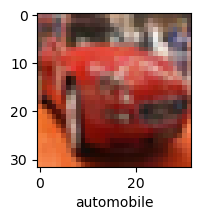

In [11]:
plot_sample(X_train,y_train,5)

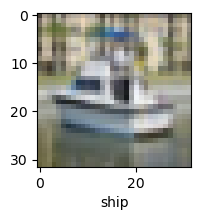

In [12]:
plot_sample(X_train,y_train,501)

In [13]:
X_train=X_train/255.0
X_test=X_test/255.0

In [14]:
ann=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(3000,activation="relu"),
    layers.Dense(1000,activation="relu"),
    layers.Dense(10,activation="softmax")
])
ann.compile(optimizer="SGD",
           loss="sparse_categorical_crossentropy",
           metrics=["accuracy"])
ann.fit(X_train,y_train,epochs=5)

C:\Users\aades\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 37ms/step - accuracy: 0.3550 - loss: 1.8100
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 38ms/step - accuracy: 0.4276 - loss: 1.6233
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 38ms/step - accuracy: 0.4552 - loss: 1.5406
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 38ms/step - accuracy: 0.4777 - loss: 1.4830
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 38ms/step - accuracy: 0.4977 - loss: 1.4306


In [15]:
from sklearn.metrics import confusion_matrix,classification_report
import numpy as np
y_pred=ann.predict(X_test)
y_pred_classes=[np.argmax(element) for element in y_pred]

print("Classification Report : \n",classification_report(y_test,y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step
Classification Report : 
               precision    recall  f1-score   support

           0       0.58      0.47      0.52      1000
           1       0.58      0.49      0.53      1000
           2       0.51      0.13      0.21      1000
           3       0.33      0.33      0.33      1000
           4       0.50      0.26      0.34      1000
           5       0.53      0.21      0.30      1000
           6       0.37      0.76      0.50      1000
           7       0.65      0.38      0.48      1000
           8       0.77      0.35      0.48      1000
           9       0.27      0.83      0.41      1000

    accuracy                           0.42     10000
   macro avg       0.51      0.42      0.41     10000
weighted avg       0.51      0.42      0.41     10000



In [18]:
import seaborn as sns

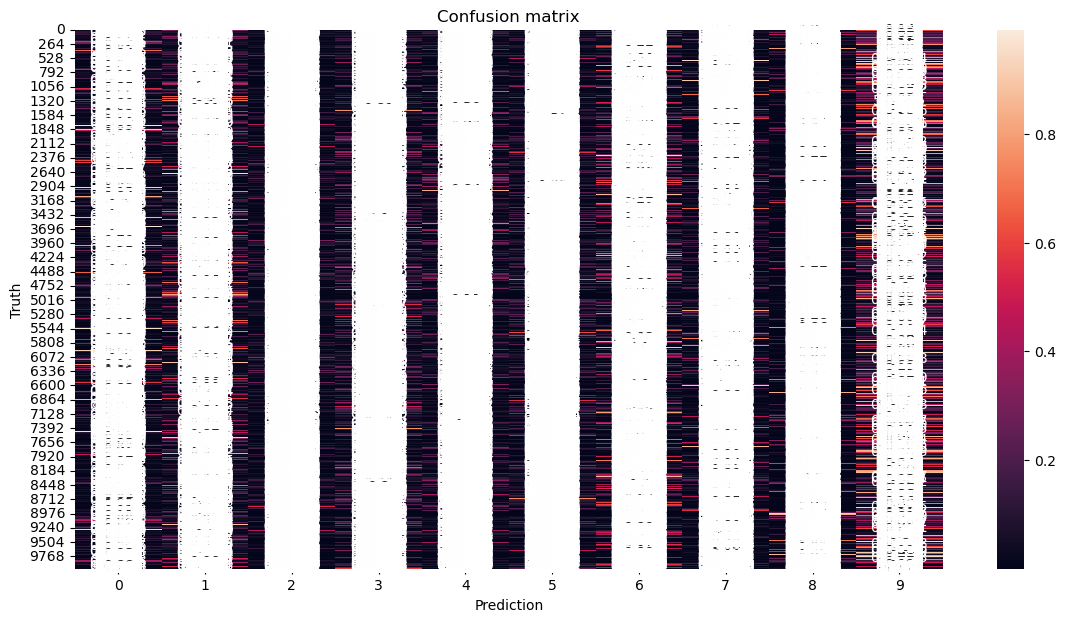

In [19]:
plt.figure(figsize=(14,7))
sns.heatmap(y_pred,annot=True)
plt.ylabel("Truth")
plt.xlabel("Prediction")
plt.title("Confusion matrix")
plt.show()

In [22]:
cnn=models.Sequential([
    layers.Conv2D(filters=32,kernel_size=(3,3),activation="relu",input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(filters=64,kernel_size=(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

In [23]:
cnn.compile(optimizer="adam",
           loss="sparse_categorical_crossentropy",
           metrics=["accuracy"])

In [24]:
cnn.fit(X_train,y_train,epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.4625 - loss: 1.4847
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6047 - loss: 1.1232
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.6572 - loss: 0.9816
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6900 - loss: 0.8968
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7122 - loss: 0.8307
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7324 - loss: 0.7709
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7499 - loss: 0.7206
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.7660 - loss: 0.6770
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.7771 - loss: 0.6418
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.7878 - loss: 0.6076


In [25]:
cnn.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6987 - loss: 0.9269


[0.9268892407417297, 0.6987000107765198]

In [27]:
y_pred=cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


array([[2.73168931e-04, 7.61981239e-04, 2.04164186e-03, 7.34704137e-01,
        1.07452888e-06, 2.19099876e-02, 3.84763093e-03, 1.19559096e-04,
        2.35497013e-01, 8.43745249e-04],
       [1.79130153e-03, 3.55560286e-03, 1.25834617e-06, 1.55109751e-06,
        1.48960320e-08, 9.78305548e-10, 6.63980693e-09, 5.55086217e-07,
        9.93594825e-01, 1.05489977e-03],
       [1.27014369e-02, 3.37453961e-01, 1.05306646e-03, 2.68569980e-02,
        4.13934467e-04, 1.68266229e-03, 1.02585950e-03, 4.00170172e-03,
        4.36347425e-01, 1.78462908e-01],
       [9.36385334e-01, 2.93025337e-02, 3.27449525e-03, 4.41653392e-04,
        2.30573511e-04, 2.48241281e-06, 2.81657831e-05, 1.15888606e-05,
        2.97804978e-02, 5.42546040e-04],
       [3.07520367e-07, 1.81249834e-06, 9.82199907e-02, 1.17000816e-02,
        1.59857944e-01, 1.00738143e-04, 7.30114102e-01, 5.17437172e-07,
        4.41600650e-06, 4.75475126e-08]], dtype=float32)

In [28]:
y_classes=[np.argmax(element) for element in y_pred]
y_classes[:5]

[3, 8, 8, 0, 6]

In [29]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

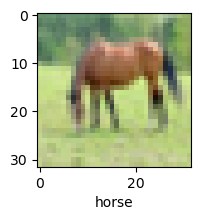

In [30]:
plot_sample(X_test,y_test,60)

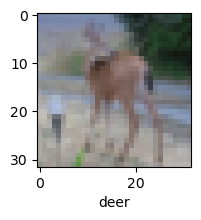

In [31]:
plot_sample(X_test,y_test,100)

In [33]:
classes[y_classes[60]]

'horse'